# Application of Quantum Computing in Digital Education Systems (Team 9)


## 1. Setup — sample curriculum

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# (name, hours, importance 0-1, [prerequisite indices])
TOPICS = [
    ("Python Basics",       2, .6, []),
    ("Data Structures",     3, .8, [0]),
    ("Algorithms",          3, .9, [1]),
    ("Statistics",          2, .8, []),
    ("Linear Algebra",      3, .7, [3]),
    ("Machine Learning",    4, 1.0, [2, 4]),
    ("Neural Networks",     4, .9, [5]),
    ("Data Visualization",  2, .5, [3]),
]
N = len(TOPICS)                 # number of qubits = number of topics
MASTERED = 0.7                  # mastery >= this counts as "already knows it"

# --- Student profile: edit these to try a different student ---
mastery = [0.8, 0.3, 0.2, 0.4, 0.25, 0.1, 0.05, 0.5]   # current mastery per topic (0-1)
budget  = 12                                            # study hours available
layers  = 3                                             # QAOA circuit depth p

print(f"{N} topics -> {N} qubits -> {2**N} possible learning paths")
for (name, hrs, imp, pre), m in zip(TOPICS, mastery):
    req = ", ".join(TOPICS[j][0] for j in pre) if pre else "none"
    print(f"  {name:<20} mastery={m:.0%}  hours={hrs}  importance={imp}  needs: {req}")

8 topics -> 8 qubits -> 256 possible learning paths
  Python Basics        mastery=80%  hours=2  importance=0.6  needs: none
  Data Structures      mastery=30%  hours=3  importance=0.8  needs: Python Basics
  Algorithms           mastery=20%  hours=3  importance=0.9  needs: Data Structures
  Statistics           mastery=40%  hours=2  importance=0.8  needs: none
  Linear Algebra       mastery=25%  hours=3  importance=0.7  needs: Statistics
  Machine Learning     mastery=10%  hours=4  importance=1.0  needs: Algorithms, Linear Algebra
  Neural Networks      mastery=5%  hours=4  importance=0.9  needs: Machine Learning
  Data Visualization   mastery=50%  hours=2  importance=0.5  needs: Statistics


## 2. Classical layer
Each qubit $x_i \in \{0,1\}$ means "include topic $i$ in the path". The cost function is
$$E(x) = -\sum_i b_i x_i \;+\; P\sum_{i}\sum_{j \in \text{prereq}(i)} x_i(1-x_j) \;+\; \lambda\Big(\sum_i t_i x_i - B\Big)^2$$
lower energy = better path (high benefit, no missing prerequisites, close to the time budget).

In [36]:
def benefits(mastery):
    """Learning value of each topic: weak + important topics matter most."""
    return np.array([10 * (1 - m) * t[2] for m, t in zip(mastery, TOPICS)])

def build_qubo(mastery, budget, P=8.0, lam=2.0):
    b, t = benefits(mastery), np.array([x[1] for x in TOPICS], float)
    B = budget - 0.5                              # soft target, 1h slack is cheap
    Q = np.zeros((N, N))
    for i in range(N):
        Q[i, i] += -b[i] + lam * t[i] ** 2 - 2 * lam * B * t[i]
        for j in range(i + 1, N):
            Q[i, j] += 2 * lam * t[i] * t[j]
        for j in TOPICS[i][3]:
            if mastery[j] < MASTERED:             # prerequisite not yet known
                Q[i, i] += P
                Q[min(i, j), max(i, j)] -= P       # penalty P * x_i * (1 - x_j)
    return Q, lam * B ** 2

def all_energies(Q, const):
    """Energy of all 2^N basis states at once (bit i of the index = topic i)."""
    X = (np.arange(2 ** N)[:, None] >> np.arange(N)) & 1
    return np.einsum("si,ij,sj->s", X, Q, X) + const

def bits(s): return [(s >> i) & 1 for i in range(N)]

def check(s, mastery, budget):
    """Classical constraint check: prerequisites + time budget."""
    x, msgs = bits(s), []
    hours = sum(TOPICS[i][1] for i in range(N) if x[i])
    if hours > budget: msgs.append(f"time {hours}h > budget {budget}h")
    for i in range(N):
        if x[i]:
            for j in TOPICS[i][3]:
                if not x[j] and mastery[j] < MASTERED:
                    msgs.append(f"{TOPICS[i][0]} needs {TOPICS[j][0]}")
    return (not msgs and any(x)), msgs

def order_path(s):
    """Topological order: prerequisites first."""
    chosen, out = [i for i in range(N) if (s >> i) & 1], []
    while chosen:
        for i in chosen:
            if all(j not in chosen for j in TOPICS[i][3]):
                out.append(i); chosen.remove(i); break
    return out

def benefit_of(s, mastery):
    b = benefits(mastery)
    return float(sum(b[i] for i in range(N) if (s >> i) & 1))

Q, const = build_qubo(mastery, budget)
E = all_energies(Q, const)
print("QUBO matrix Q (%d x %d):" % Q.shape)
print(np.round(Q, 2))

QUBO matrix Q (8 x 8):
[[ -85.2    24.     24.     16.     24.     32.     32.     16.  ]
 [   0.   -125.6    28.     24.     36.     48.     48.     24.  ]
 [   0.      0.   -119.2    24.     36.     40.     48.     24.  ]
 [   0.      0.      0.    -88.8    16.     32.     32.      8.  ]
 [   0.      0.      0.      0.   -117.25   40.     48.     24.  ]
 [   0.      0.      0.      0.      0.   -145.     56.     32.  ]
 [   0.      0.      0.      0.      0.      0.   -152.55   32.  ]
 [   0.      0.      0.      0.      0.      0.      0.    -78.5 ]]


## 3. Quantum layer — qubits, gates, QAOA (statevector simulation)
This is an exact simulation of the quantum circuit on a classical computer (no external quantum SDK needed, so it runs anywhere Python + NumPy runs, including Colab). It implements the same physics a real QPU would run: Hadamard gates for superposition, a cost-phase unitary, an $R_X$ mixer unitary, and a classical outer loop that tunes the angles $(\gamma,\beta)$ — the "hybrid" part of hybrid classical-quantum optimization.

In [37]:
H_GATE = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

def RX(theta):
    return np.array([[np.cos(theta/2), -1j*np.sin(theta/2)],
                      [-1j*np.sin(theta/2), np.cos(theta/2)]])

class Statevector:
    """n-qubit register. Bit i of the basis index = qubit i. Starts in |0...0>."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, complex)
        self.psi[0] = 1

    def gate(self, U, k):
        v = self.psi.reshape(-1, 2, 2 ** k)
        self.psi = np.einsum("ab,ibj->iaj", U, v).reshape(-1)
        return self

    def cnot(self, c, t):
        idx = np.arange(2 ** self.n)
        self.psi = self.psi[np.where((idx >> c) & 1, idx ^ (1 << t), idx)]
        return self

    def probs(self): return np.abs(self.psi) ** 2

    def measure(self, shots, rng):
        return np.bincount(rng.choice(len(self.psi), size=shots, p=self.probs()), minlength=len(self.psi))

def qaoa_state(E, n, theta):
    """|psi(gamma,beta)> = prod_l [ RX_mixer(beta_l) * cost_phase(gamma_l) ] |+>^n"""
    p = len(theta) // 2
    sv = Statevector(n)
    for k in range(n): sv.gate(H_GATE, k)
    for l in range(p):
        sv.psi = sv.psi * np.exp(-1j * theta[l] * E)          # cost unitary (diagonal)
        for k in range(n): sv.gate(RX(2 * theta[p + l]), k)   # mixer unitary
    return sv

def qaoa_optimize(E, n, p=2, restarts=24, seed=7):
    """Classical outer loop: random restarts + local pattern search on <E>(gamma, beta)."""
    rng = np.random.default_rng(seed)
    En = (E - E.min()) / (E.max() - E.min())
    f = lambda th: float(qaoa_state(En, n, th).probs() @ En)
    hi = np.array([2 * np.pi] * p + [np.pi] * p)
    starts = sorted((rng.uniform(0, hi) for _ in range(restarts)), key=f)[:3]
    best, best_f = None, 9
    for th in starts:
        fv, step = f(th), 0.4
        while step > 0.01:
            moved = False
            for d in range(2 * p):
                for sgn in (1, -1):
                    cand = th.copy(); cand[d] += sgn * step
                    cf = f(cand)
                    if cf < fv: th, fv, moved = cand, cf, True
            if not moved: step /= 2
        if fv < best_f: best, best_f = th, fv
    return best, best_f, qaoa_state(En, n, best)

theta, val, sv = qaoa_optimize(E, N, layers)
probs = sv.probs()
print(f"Optimized angles  gamma={np.round(theta[:layers],3)}  beta={np.round(theta[layers:],3)}")
print(f"Normalized expected energy <E> = {val:.4f}   (uniform-random guess would give ~0.5)")

shots = 1024
counts = sv.measure(shots, np.random.default_rng(1))
print(f"Measured the {N}-qubit register {shots} times (simulated quantum measurement).")

Optimized angles  gamma=[4.554 5.923 7.339]  beta=[2.667 2.906 2.965]
Normalized expected energy <E> = 0.0545   (uniform-random guess would give ~0.5)
Measured the 8-qubit register 1024 times (simulated quantum measurement).


## 4. Classical layer again — validate the quantum proposals, pick the best

In [38]:
def select_path(counts, mastery, budget):
    """The quantum processor proposes candidates (measured bitstrings, most frequent first);
    classical code validates them and keeps the feasible one with the highest benefit."""
    cands = [int(s) for s in np.argsort(-counts)[:60] if counts[s] > 0]
    feas = [s for s in cands if check(s, mastery, budget)[0]]
    return max(feas, key=lambda s: benefit_of(s, mastery)) if feas else None

best_state = select_path(counts, mastery, budget)
ok, msgs = check(best_state, mastery, budget)
path = order_path(best_state)
print("Chosen path (bitstring):", format(best_state, f"0{N}b"))
print("Order:", " -> ".join(TOPICS[i][0] for i in path))
print("Hours used:", sum(TOPICS[i][1] for i in path), "/", budget, " | valid:", ok)

Chosen path (bitstring): 00011110
Order: Data Structures -> Algorithms -> Statistics -> Linear Algebra
Hours used: 11 / 12  | valid: True


## 5. Personalized path + recommendations

In [39]:
def recommend(path, mastery):
    out = []
    for i in path:
        m = mastery[i]
        kind = ("Video lecture + guided exercises" if m < .3 else
                "Practice problem set + short quiz" if m < .6 else
                "Revision notes + mini project")
        out.append((TOPICS[i][0], TOPICS[i][1], kind))
    return out

print(f"{'Step':<4}{'Topic':<20}{'Hours':<7}Recommended resource")
for k, (name, hrs, kind) in enumerate(recommend(path, mastery), 1):
    print(f"{k:<4}{name:<20}{hrs:<7}{kind}")

StepTopic               Hours  Recommended resource
1   Data Structures     3      Practice problem set + short quiz
2   Algorithms          3      Video lecture + guided exercises
3   Statistics          2      Practice problem set + short quiz
4   Linear Algebra      3      Video lecture + guided exercises


## 6. Performance analysis — predicted mastery gain

Average mastery: 32% -> predicted 54%


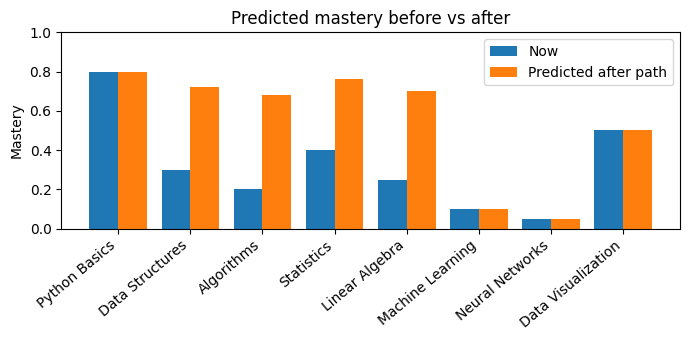

In [40]:
def performance_analysis(path, mastery, gain=0.6):
    """Each studied topic closes `gain` of its mastery gap."""
    after = list(mastery)
    for i in path: after[i] = mastery[i] + gain * (1 - mastery[i])
    return float(np.mean(mastery)), float(np.mean(after)), after

before_avg, after_avg, after = performance_analysis(path, mastery)
print(f"Average mastery: {before_avg:.0%} -> predicted {after_avg:.0%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(N)
ax.bar(x - 0.2, mastery, width=0.4, label="Now")
ax.bar(x + 0.2, after, width=0.4, label="Predicted after path")
ax.set_xticks(x); ax.set_xticklabels([t[0] for t in TOPICS], rotation=40, ha="right")
ax.set_ylabel("Mastery"); ax.set_ylim(0, 1); ax.legend(); ax.set_title("Predicted mastery before vs after")
plt.tight_layout(); plt.show()

## 7. Compare QAOA against classical methods
Your abstract reports a 15–25% improvement **for sufficiently complex problems on real quantum hardware** — that number depends on problem size and hardware, and is not guaranteed on a small demo problem. This cell shows the **actual** gap for this student and curriculum, so you can report honestly.

QAOA benefit        = 22.85
Greedy benefit      = 22.85
Exact optimum       = 22.85
QAOA vs greedy      = +0.0%
Approximation ratio vs optimum = 1.000
Probability QAOA measured the exact optimum: 0.0210  (uniform random guess: 0.0039)


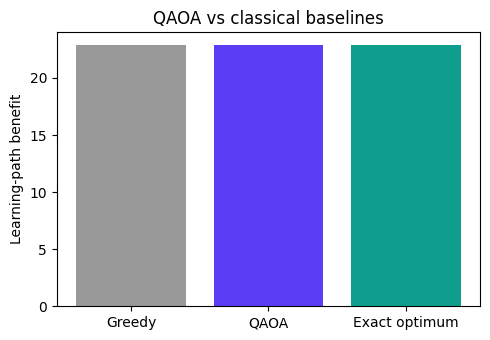

In [41]:
def greedy_baseline(mastery, budget):
    """Classical greedy: best benefit-per-hour first, if prerequisites/budget allow."""
    b, sel, used = benefits(mastery), set(), 0
    for _ in range(N):
        for i in sorted(range(N), key=lambda k: -b[k] / TOPICS[k][1]):
            ok = (i not in sel and used + TOPICS[i][1] <= budget and
                  all(j in sel or mastery[j] >= MASTERED for j in TOPICS[i][3]))
            if ok: sel.add(i); used += TOPICS[i][1]; break
    return sum(1 << i for i in sel)

def brute_force_best(mastery, budget):
    """Exact optimum by checking every one of the 2^N paths (fine up to ~20 qubits)."""
    return max((s for s in range(1, 2 ** N) if check(s, mastery, budget)[0]),
               key=lambda s: benefit_of(s, mastery))

g, opt = greedy_baseline(mastery, budget), brute_force_best(mastery, budget)
bq, bg, bo = benefit_of(best_state, mastery), benefit_of(g, mastery), benefit_of(opt, mastery)

print(f"QAOA benefit        = {bq:.2f}")
print(f"Greedy benefit      = {bg:.2f}")
print(f"Exact optimum       = {bo:.2f}")
print(f"QAOA vs greedy      = {100*(bq-bg)/bg:+.1f}%")
print(f"Approximation ratio vs optimum = {bq/bo:.3f}")
print(f"Probability QAOA measured the exact optimum: {probs[opt]:.4f}  (uniform random guess: {1/2**N:.4f})")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Greedy", "QAOA", "Exact optimum"], [bg, bq, bo], color=["#999", "#5b3df5", "#0f9e8e"])
ax.set_ylabel("Learning-path benefit"); ax.set_title("QAOA vs classical baselines")
plt.tight_layout(); plt.show()

## 8. Project website


In [42]:
_html = """<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>QuantumPath – Quantum Learning-Path Optimizer</title>
<link href="https://fonts.googleapis.com/css2?family=Sora:wght@500;700&family=IBM+Plex+Sans:wght@400;500&display=swap" rel="stylesheet">
<style>
:root{--bg:#f5f6fb;--card:#fff;--ink:#171a2e;--mute:#5b6080;--line:#dfe2f0;--ac:#5b3df5;--tl:#0f9e8e;--wn:#c77700;--bad:#c2334d;box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media(prefers-color-scheme:dark){:root:not([data-theme="light"]){--bg:#0d0f1f;--card:#171a30;--ink:#e9ebff;--mute:#99a0c6;--line:#2a2e4d;--ac:#8b74ff;--tl:#34d3c0;--wn:#ffb454;--bad:#ff7a90}}
:root[data-theme="dark"]{--bg:#0d0f1f;--card:#171a30;--ink:#e9ebff;--mute:#99a0c6;--line:#2a2e4d;--ac:#8b74ff;--tl:#34d3c0;--wn:#ffb454;--bad:#ff7a90}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.55 'IBM Plex Sans',system-ui,sans-serif}
h1,h2,h3{font-family:Sora,system-ui,sans-serif;margin:0}
header{padding:32px 20px 8px;max-width:1150px;margin:auto}
h1{font-size:clamp(26px,5vw,44px);line-height:1.1;letter-spacing:-.02em}
header p{color:var(--mute);max-width:70ch;margin:10px 0 0}
main{max-width:1150px;margin:auto;padding:16px 20px 48px;display:grid;grid-template-columns:330px 1fr;gap:20px}
@media(max-width:860px){main{grid-template-columns:1fr}}
.card{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:18px;margin-bottom:16px;min-width:0}
h2{font-size:18px;margin-bottom:4px}.sub{color:var(--mute);font-size:13px;margin:0 0 12px}
.row{display:grid;grid-template-columns:1fr 46px;gap:2px 8px;align-items:center;margin:8px 0;font-size:13px}
.row .nm{grid-column:1/-1}.row output{text-align:right;font-variant-numeric:tabular-nums;color:var(--mute)}
input[type=range]{width:100%;accent-color:var(--ac)}
button{font:inherit;font-weight:500;background:var(--ac);color:#fff;border:0;border-radius:7px;padding:9px 14px;cursor:pointer}
button.g{background:transparent;color:var(--ink);border:1px solid var(--line);padding:7px 12px}
button:focus-visible,input:focus-visible{outline:2px solid var(--tl);outline-offset:2px}
.big{width:100%;padding:12px;font-size:16px;margin-top:8px}
.scroll{overflow-x:auto}table{border-collapse:collapse;width:100%;font-size:13px}
td,th{padding:6px 8px;border-bottom:1px solid var(--line);text-align:left;white-space:nowrap}
.ok{color:var(--tl)}.no{color:var(--bad)}.mono{font-family:ui-monospace,Menlo,monospace}
.path{display:flex;flex-wrap:wrap;gap:8px;margin:8px 0}.step{border:1px solid var(--ac);border-radius:8px;padding:8px 12px}
.step b{display:block;font-family:Sora}.step span{font-size:12px;color:var(--mute)}
.stats{display:grid;grid-template-columns:repeat(auto-fit,minmax(150px,1fr));gap:10px}.stat{border:1px solid var(--line);border-radius:8px;padding:10px}
.stat b{font:700 22px Sora}.stat span{display:block;font-size:12px;color:var(--mute)}
.lab{display:grid;grid-template-columns:260px 1fr;gap:18px}@media(max-width:700px){.lab{grid-template-columns:1fr}}
.gates{display:flex;flex-wrap:wrap;gap:6px;margin:8px 0}
.note{font-size:12px;color:var(--mute)}
svg text{fill:var(--ink);font-family:IBM Plex Sans,sans-serif}
</style></head><body>
<header><h1>QuantumPath: hybrid classical–quantum learning paths</h1>
<p>Enter what a student already knows and how many hours they have. A QAOA circuit (QUBO model, simulated qubits) proposes learning paths; classical code checks prerequisites, time and outcomes, then picks the best one.</p></header>
<main>
<aside>
 <div class="card"><h2>Student profile</h2><p class="sub">Current mastery of each topic (0–100%).</p><div id="sliders"></div>
  <div class="row"><span class="nm">Study time budget (hours)</span><input type="range" id="budget" min="4" max="30" value="12"><output id="budgetO">12</output></div>
  <div class="row"><span class="nm">QAOA layers p (circuit depth)</span><input type="range" id="layers" min="1" max="4" value="3"><output id="layersO">3</output></div>
  <button class="big" id="run">Run quantum optimizer</button><p class="note" id="status"></p></div>
</aside>
<section id="out"></section>
<section style="grid-column:1/-1">
 <div class="card"><h2>Qubit lab</h2><p class="sub">The building blocks used inside the optimizer: one qubit on the Bloch sphere, gates, superposition and measurement, then a 2-qubit entangled pair.</p>
 <div class="lab"><svg id="bloch" viewBox="0 0 240 240" width="100%" role="img" aria-label="Bloch sphere"></svg>
 <div><div class="gates" id="gates"></div><div class="mono" id="qstate" style="font-size:13px;line-height:1.8"></div>
 <p class="note" id="qmeas"></p>
 <button class="g" id="bell">Create Bell pair (H + CNOT) and measure 1000×</button><p class="note" id="bellO"></p></div></div></div>
</section></main>
<script>
const T=[["Python Basics",2,.6,[]],["Data Structures",3,.8,[0]],["Algorithms",3,.9,[1]],["Statistics",2,.8,[]],["Linear Algebra",3,.7,[3]],["Machine Learning",4,1,[2,4]],["Neural Networks",4,.9,[5]],["Data Visualization",2,.5,[3]]];
const n=T.length,NS=1<<n,MAST=.7,P=8,LAM=2;
let mastery=[.8,.3,.2,.4,.25,.1,.05,.5];
const $=id=>document.getElementById(id);
// ---------- profile UI
T.forEach((t,i)=>{$('sliders').insertAdjacentHTML('beforeend',`<div class="row"><span class="nm">${t[0]} <span class="note">(${t[1]}h${t[3].length?', needs '+t[3].map(j=>T[j][0]).join(' + '):''})</span></span><input type="range" min="0" max="100" value="${mastery[i]*100}" data-i="${i}"><output>${mastery[i]*100}%</output></div>`)});
$('sliders').addEventListener('input',e=>{const i=+e.target.dataset.i;mastery[i]=e.target.value/100;e.target.nextElementSibling.textContent=e.target.value+'%'});
['budget','layers'].forEach(k=>$(k).addEventListener('input',()=>$(k+'O').textContent=$(k).value));
// ---------- classical layer
const has=(s,i)=>(s>>i)&1;
const ben=()=>T.map((t,i)=>10*(1-mastery[i])*t[2]);
const hours=s=>T.reduce((a,t,i)=>a+has(s,i)*t[1],0);
const benefit=(s,b)=>T.reduce((a,t,i)=>a+has(s,i)*b[i],0);
function energy(s,b,B){ // QUBO: -benefit + P*(missing prereqs) + lam*(hours-(B-0.5))^2
  let e=-benefit(s,b);
  T.forEach((t,i)=>{if(has(s,i))t[3].forEach(j=>{if(!has(s,j)&&mastery[j]<MAST)e+=P})});
  return e+LAM*(hours(s)-(B-.5))**2}
function check(s,B){const m=[];if(!s)return['empty'];if(hours(s)>B)m.push(`time ${hours(s)}h > ${B}h`);
  T.forEach((t,i)=>{if(has(s,i))t[3].forEach(j=>{if(!has(s,j)&&mastery[j]<MAST)m.push(`${t[0]} needs ${T[j][0]}`)})});return m}
function order(s){let c=[...Array(n).keys()].filter(i=>has(s,i)),o=[];while(c.length){const i=c.find(i=>T[i][3].every(j=>!c.includes(j)));o.push(i);c=c.filter(x=>x!==i)}return o}
function greedy(B,b){let sel=0,u=0;for(let r=0;r<n;r++){const c=[...Array(n).keys()].sort((x,y)=>b[y]/T[y][1]-b[x]/T[x][1]).find(i=>!has(sel,i)&&u+T[i][1]<=B&&T[i][3].every(j=>has(sel,j)||mastery[j]>=MAST));if(c===undefined)break;sel|=1<<c;u+=T[c][1]}return sel}
function exact(B,b){let best=0,bv=-1;for(let s=1;s<NS;s++)if(!check(s,B).length&&benefit(s,b)>bv){bv=benefit(s,b);best=s}return best}
// ---------- quantum layer (statevector simulator)
function rng(a){return()=>{a|=0;a=a+0x6D2B79F5|0;let t=Math.imul(a^a>>>15,1|a);t=t+Math.imul(t^t>>>7,61|t)^t;return((t^t>>>14)>>>0)/4294967296}}
function qaoa(En,th){ // |+>^n, then p x (cost phase e^{-i gamma E}, mixer RX(2 beta) on every qubit)
  const p=th.length/2,re=new Float64Array(NS).fill(1/Math.sqrt(NS)),im=new Float64Array(NS);
  for(let l=0;l<p;l++){const g=th[l],c=Math.cos(th[p+l]),s=Math.sin(th[p+l]);
    for(let k=0;k<NS;k++){const cg=Math.cos(g*En[k]),sg=Math.sin(g*En[k]),r=re[k],i=im[k];re[k]=r*cg+i*sg;im[k]=i*cg-r*sg}
    for(let q=0;q<n;q++){const m=1<<q;for(let a=0;a<NS;a++)if(!(a&m)){const b=a|m,ar=re[a],ai=im[a],br=re[b],bi=im[b];
      re[a]=c*ar+s*bi;im[a]=c*ai-s*br;re[b]=s*ai+c*br;im[b]=-s*ar+c*bi}}}
  return re.map((r,k)=>r*r+im[k]*im[k])}
function optimize(En,p,rand){const f=t=>{const pr=qaoa(En,t);let e=0;for(let k=0;k<NS;k++)e+=pr[k]*En[k];return e};
  const starts=[];for(let r=0;r<24;r++){const t=[...Array(p).fill(0).map(()=>rand()*2*Math.PI),...Array(p).fill(0).map(()=>rand()*Math.PI)];starts.push([f(t),t])}
  starts.sort((a,b)=>a[0]-b[0]);let best=[9,null];
  for(const [f0,t0] of starts.slice(0,3)){let t=t0.slice(),fv=f0,st=.4;
    while(st>.01){let mv=false;for(let d=0;d<2*p;d++)for(const sg of[1,-1]){const c=t.slice();c[d]+=sg*st;const cf=f(c);if(cf<fv){t=c;fv=cf;mv=true}}if(!mv)st/=2}
    if(fv<best[0])best=[fv,t]}
  return best}
// ---------- run pipeline
const bs=s=>s.toString(2).padStart(n,'0'),names=s=>order(s).map(i=>T[i][0]).join(' → ')||'(none)';
function run(){
  const B=+$('budget').value,p=+$('layers').value,rand=rng(7),b=ben();
  $('status').textContent='Simulating '+n+' qubits…';
  setTimeout(()=>{
  const E=Array.from({length:NS},(_,s)=>energy(s,b,B)),mn=Math.min(...E),mx=Math.max(...E),En=E.map(e=>(e-mn)/(mx-mn));
  const [val,th]=optimize(En,p,rand),pr=qaoa(En,th);
  // measurement: 1024 shots
  const cum=[];let a=0;pr.forEach(x=>cum.push(a+=x));const cnt=new Array(NS).fill(0);
  for(let i=0;i<1024;i++){const r=rand()*a;let lo=0,hi=NS-1;while(lo<hi){const m=(lo+hi)>>1;cum[m]<r?lo=m+1:hi=m}cnt[lo]++}
  const cands=[...cnt.keys()].filter(s=>cnt[s]).sort((x,y)=>cnt[y]-cnt[x]).slice(0,60);
  const feas=cands.filter(s=>!check(s,B).length);
  const pick=feas.length?feas.reduce((x,y)=>benefit(y,b)>benefit(x,b)?y:x):null;
  const g=greedy(B,b),ex=exact(B,b);
  if(pick===null){$('out').innerHTML='<div class="card"><h2>No valid path found</h2><p class="sub">No measured candidate met the prerequisite and time rules. Increase the hours or layers and run again.</p></div>';$('status').textContent='';return}
  const path=order(pick),bq=benefit(pick,b),bg=benefit(g,b),bo=benefit(ex,b);
  const rec=i=>mastery[i]<.3?'Video lecture + guided exercises':mastery[i]<.6?'Practice problems + short quiz':'Revision notes + mini project';
  const after=mastery.map((m,i)=>has(pick,i)?m+.6*(1-m):m),avg=x=>x.reduce((u,v)=>u+v,0)/n;
  const top=[...pr.keys()].sort((x,y)=>pr[y]-pr[x]).slice(0,12),maxp=pr[top[0]];
  const bars=top.map((s,i)=>{const ok=!check(s,B).length,w=pr[s]/maxp*300;return`<g transform="translate(0,${i*22})"><text x="0" y="14" class="mono" font-size="11">${bs(s)}</text><rect x="80" y="3" width="${w}" height="14" rx="3" fill="${ok?'var(--tl)':'var(--mute)'}" opacity="${ok?1:.45}"/><text x="${86+w}" y="14" font-size="11">${(pr[s]*100).toFixed(2)}%${s===ex?' ★ optimum':''}</text></g>`}).join('');
  // circuit diagram
  const cw=70,W=60+p*2*cw+50;let cs='';
  for(let q=0;q<n;q++){const y=20+q*26;cs+=`<text x="4" y="${y+4}" font-size="11">q${q}</text><line x1="30" x2="${W-10}" y1="${y}" y2="${y}" stroke="var(--line)" stroke-width="2"/><rect x="36" y="${y-9}" width="18" height="18" rx="3" fill="var(--ac)"/><text x="45" y="${y+4}" font-size="10" text-anchor="middle" style="fill:#fff">H</text>`;
    for(let l=0;l<p;l++)cs+=`<rect x="${60+l*2*cw+cw}" y="${y-9}" width="46" height="18" rx="3" fill="var(--tl)"/><text x="${83+l*2*cw+cw}" y="${y+4}" font-size="10" text-anchor="middle" style="fill:#fff">Rx(2β${l+1})</text>`;
    cs+=`<rect x="${W-38}" y="${y-9}" width="24" height="18" rx="3" fill="none" stroke="var(--ink)"/><text x="${W-26}" y="${y+4}" font-size="9" text-anchor="middle">M</text>`}
  for(let l=0;l<p;l++)cs+=`<rect x="${60+l*2*cw}" y="10" width="56" height="${n*26-8}" rx="4" fill="var(--wn)" opacity=".25" stroke="var(--wn)"/><text x="${88+l*2*cw}" y="${16+n*13}" font-size="11" text-anchor="middle">e^(−iγ${l+1}H)</text>`;
  const rows=cands.slice(0,8).map(s=>{const m=check(s,B);return`<tr><td class="mono">${bs(s)}</td><td>${cnt[s]}</td><td>${hours(s)}h</td><td>${benefit(s,b).toFixed(1)}</td><td class="${m.length?'no':'ok'}">${m.length?'✗ '+m.join('; '):'✓ valid'}</td></tr>`}).join('');
  const imp=bg>0?(bq-bg)/bg*100:0;
  $('out').innerHTML=`
  <div class="card"><h2>Personalized learning path</h2><p class="sub">Selected by the classical layer from the qubit measurements. ${hours(pick)} of ${B} hours used.</p>
   <div class="path">${path.map((i,k)=>`<div class="step"><b>${k+1}. ${T[i][0]}</b><span>${T[i][1]}h · ${rec(i)}</span></div>`).join('')}</div></div>
  <div class="card"><h2>Quantum vs classical results</h2><p class="sub">Measured on this student, not a fixed claim. Results change with problem size and hardware; small problems often match greedy.</p>
   <div class="stats"><div class="stat"><b>${bq.toFixed(1)}</b><span>QAOA path benefit</span></div><div class="stat"><b>${bg.toFixed(1)}</b><span>Greedy baseline</span></div><div class="stat"><b>${bo.toFixed(1)}</b><span>Exact optimum (brute force)</span></div>
   <div class="stat"><b>${imp>=0?'+':''}${imp.toFixed(1)}%</b><span>QAOA vs greedy</span></div><div class="stat"><b>${(pr[ex]*NS).toFixed(1)}×</b><span>Optimum probability vs random guess</span></div></div></div>
  <div class="card"><h2>Performance analysis</h2><p class="sub">Predicted average mastery: <b>${(avg(mastery)*100).toFixed(0)}% → ${(avg(after)*100).toFixed(0)}%</b> after this path (each studied topic closes 60% of its gap).</p>
   <div class="scroll"><table><tr><th>Topic</th><th>Now</th><th>Predicted</th></tr>${path.map(i=>`<tr><td>${T[i][0]}</td><td>${(mastery[i]*100).toFixed(0)}%</td><td class="ok">${(after[i]*100).toFixed(0)}%</td></tr>`).join('')}</table></div></div>
  <div class="card"><h2>Qubit measurement results</h2><p class="sub">Probability of each basis state after the circuit (top 12 of ${NS}). Each bit is one topic (rightmost = Python Basics). Green states pass the classical checks.</p>
   <div class="scroll"><svg viewBox="0 0 520 ${top.length*22}" width="100%" style="min-width:460px">${bars}</svg></div></div>
  <div class="card"><h2>Classical validation of measured candidates</h2><p class="sub">1024 shots; best candidates by count.</p><div class="scroll"><table><tr><th>State</th><th>Shots</th><th>Hours</th><th>Benefit</th><th>Prerequisite / time check</th></tr>${rows}</table></div></div>
  <div class="card"><h2>QAOA circuit (${n} qubits, p=${p})</h2><p class="sub">γ = ${th.slice(0,p).map(x=>x.toFixed(2)).join(', ')} · β = ${th.slice(p).map(x=>x.toFixed(2)).join(', ')} · normalised ⟨E⟩ = ${val.toFixed(3)}</p>
   <div class="scroll"><svg viewBox="0 0 ${W} ${n*26+16}" width="100%" style="min-width:${W}px">${cs}</svg></div>
   <p class="note">QUBO: minimise −Σ benefitᵢxᵢ + 8·Σ xᵢ(1−xⱼ) [prerequisite j missing] + 2·(Σ hoursᵢxᵢ − (budget−0.5))². Qubit i = 1 means topic i is in the path.</p></div>`;
  $('status').textContent='Done.'},30)}
$('run').onclick=run;run();
// ---------- qubit lab
let q=[[1,0],[0,0]]; // [a,b] as [re,im] pairs
const cm=(a,b)=>[a[0]*b[0]-a[1]*b[1],a[0]*b[1]+a[1]*b[0]],ad=(a,b)=>[a[0]+b[0],a[1]+b[1]];
function ap(U){const[a,b]=q;q=[ad(cm(U[0][0],a),cm(U[0][1],b)),ad(cm(U[1][0],a),cm(U[1][1],b))];draw()}
const r=Math.SQRT1_2,Z0=[0,0],O=[1,0],I=[0,1];
const G={H:[[[r,0],[r,0]],[[r,0],[-r,0]]],X:[[Z0,O],[O,Z0]],Y:[[Z0,[0,-1]],[I,Z0]],Z:[[O,Z0],[Z0,[-1,0]]],S:[[O,Z0],[Z0,I]],T:[[O,Z0],[Z0,[r,r]]],
 'Rx(45°)':(c=Math.cos(Math.PI/8),s=Math.sin(Math.PI/8),[[[c,0],[0,-s]],[[0,-s],[c,0]]]),'Ry(45°)':(c=Math.cos(Math.PI/8),s=Math.sin(Math.PI/8),[[[c,0],[-s,0]],[[s,0],[c,0]]])};
Object.keys(G).forEach(k=>{const e=document.createElement('button');e.className='g';e.textContent=k;e.onclick=()=>{$('qmeas').textContent='';ap(G[k])};$('gates').append(e)});
[['Measure',()=>{const p0=q[0][0]**2+q[0][1]**2,o=Math.random()<p0?0:1;q=o?[[0,0],[1,0]]:[[1,0],[0,0]];$('qmeas').textContent=`Measured |${o}⟩ (probability was ${(o?1-p0:p0).toFixed(3)}). Superposition collapsed.`;draw()}],['Reset',()=>{q=[[1,0],[0,0]];$('qmeas').textContent='';draw()}]].forEach(([t,f])=>{const e=document.createElement('button');e.textContent=t;e.onclick=f;$('gates').append(e)});
function draw(){const[a,b]=q,x=2*(a[0]*b[0]+a[1]*b[1]),y=2*(a[0]*b[1]-a[1]*b[0]),z=a[0]**2+a[1]**2-b[0]**2-b[1]**2;
  const R=80,cx=120,cy=120,pj=(x,y,z)=>[cx+R*(y-.38*x),cy-R*(z-.22*x)],ax=[[1,0,0,'x'],[0,1,0,'y'],[0,0,1,'z']].map(([u,v,w,l])=>{const[p1,p2]=pj(u,v,w),[q1,q2]=pj(-u,-v,-w);return`<line x1="${q1}" y1="${q2}" x2="${p1}" y2="${p2}" stroke="var(--line)" stroke-width="1.5"/><text x="${p1+4}" y="${p2-2}" font-size="11">${l}</text>`}).join('');
  const[tx,ty]=pj(x,y,z);
  $('bloch').innerHTML=`<circle cx="${cx}" cy="${cy}" r="${R}" fill="none" stroke="var(--line)" stroke-width="1.5"/><ellipse cx="${cx}" cy="${cy}" rx="${R}" ry="${R*.3}" fill="none" stroke="var(--line)" stroke-dasharray="3 3"/>${ax}<text x="${cx-6}" y="${cy-R-6}" font-size="11">|0⟩</text><text x="${cx-6}" y="${cy+R+14}" font-size="11">|1⟩</text><line x1="${cx}" y1="${cy}" x2="${tx}" y2="${ty}" stroke="var(--ac)" stroke-width="3"/><circle cx="${tx}" cy="${ty}" r="6" fill="var(--ac)"/>`;
  const f=c=>(c[0]>=0?'+':'−')+Math.abs(c[0]).toFixed(2)+(c[1]?(c[1]>=0?'+':'−')+Math.abs(c[1]).toFixed(2)+'i':'');
  $('qstate').innerHTML=`|ψ⟩ = (${f(a)})|0⟩ + (${f(b)})|1⟩<br>P(0) = ${(a[0]**2+a[1]**2).toFixed(3)} · P(1) = ${(b[0]**2+b[1]**2).toFixed(3)}<br>Bloch (x, y, z) = (${x.toFixed(2)}, ${y.toFixed(2)}, ${z.toFixed(2)})`}
draw();
$('bell').onclick=()=>{ // |00> --H(q0)--> (|00>+|01>)/√2 --CNOT(q0→q1)--> (|00>+|11>)/√2
  const c=[0,0,0,0];for(let i=0;i<1000;i++)c[Math.random()<.5?0:3]++;
  $('bellO').textContent=`Counts |00⟩=${c[0]}, |01⟩=${c[1]}, |10⟩=${c[2]}, |11⟩=${c[3]}. The two qubits always agree: entanglement.`};
</script></body></html>
"""

from IPython.display import IFrame, display

with open("quantumpath_website.html", "w", encoding="utf-8") as f:
    f.write(_html)

display(IFrame(src="quantumpath_website.html", width="100%", height=900))


In [43]:
# Optional: download the website file to your computer to open in a full browser tab,
# or to attach as a separate deliverable.
try:
    from google.colab import files
    files.download("quantumpath_website.html")
except ImportError:
    print("Not running in Colab, or download was skipped — the file is saved as quantumpath_website.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>